# MAST query -- SDSS J172637.24+264127.6

Goal: test `io.query_mast`, `io.download_mast_spectra` and
`io.read_sdss_spec` on a real target: search MAST, download the
spectrum and plot it.

MAST only holds one spectrum for this object (SDSS, plate-MJD-fiber
2182-53905-0101, no HST data). Wavelengths in Angstrom, vacuum.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from spectral_diag.io import query_mast, download_mast_spectra, read_sdss_spec

## Search

In [3]:
obs = query_mast("SDSS J172637.24+264127.6")
obs["obs_collection", "instrument_name", "obs_id", "em_min", "em_max"]

obs_collection,instrument_name,obs_id,em_min,em_max
str4,str17,str28,float64,float64
SDSS,SDSS Spectrograph,sdss_spectro_2182-53905-0101,380.0,920.0


## Download

`productSubGroupDescription="SPECTRA"` keeps the per-object files
(`spec` and `spec-lite`); `max_size_mb` skips the catalogue-wide
`specObj-dr17.fits` (~7 GB) that MAST also attaches to SDSS
observations.

In [4]:
paths = download_mast_spectra(
    obs, download_dir="../data/mast", productSubGroupDescription="SPECTRA"
)
paths

INFO: Found cached file ../data/mast/spec-lite-2182-53905-0101.fits with expected size 172800. [astroquery.query]
INFO: Found cached file ../data/mast/spec-2182-53905-0101.fits with expected size 748800. [astroquery.query]


[PosixPath('../data/mast/spec-lite-2182-53905-0101.fits'),
 PosixPath('../data/mast/spec-2182-53905-0101.fits')]

In [5]:
path = next(p for p in paths if p.name.startswith("spec-lite"))
spec = read_sdss_spec(path)
print(spec.meta)
print(f"{spec.wave.size} pixels, {spec.wave.min():.1f}-{spec.wave.max():.1f} A")
print(f"median S/N = {np.median(spec.flux / spec.error):.1f}")

{'instrument': 'SDSS', 'source': 'spec-lite-2182-53905-0101.fits', 'obs_id': '2182-53905-0101', 'ra': 261.6552, 'dec': 26.690992, 'mjd': 53905, 'exptime': 3900.4, 'wave_frame': 'vacuum, heliocentric', 'flux_unit': '1e-17 erg s^-1 cm^-2 Angstrom^-1', 'fwhm_kms': 145.46721097817988, 'R': 2060.893695452571, 'snr': 61.5799674987793, 'z': -0.00012310095189604908, 'z_err': 4.0423092286800966e-06, 'class': 'STAR', 'subclass': 'A0'}
3772 pixels, 3811.5-9206.6 A
median S/N = 61.6


## Plot

The SDSS pipeline classifies it as an A0 star at z ~ 0, so the
spectrum is dominated by pressure-broadened Balmer absorption lines.

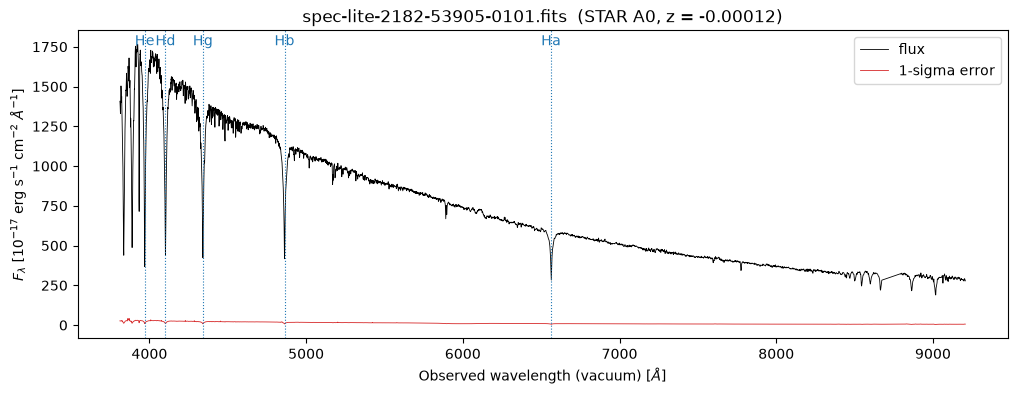

In [6]:
# Balmer lines, vacuum rest wavelengths, Angstrom
balmer = {"Ha": 6564.61, "Hb": 4862.68, "Hg": 4341.69, "Hd": 4102.89, "He": 3971.20}
z = spec.meta["z"]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(spec.wave, spec.flux, lw=0.6, color="k", label="flux")
ax.plot(spec.wave, spec.error, lw=0.6, color="C3", label="1-sigma error")
for name, w0 in balmer.items():
    ax.axvline(w0 * (1 + z), color="C0", ls=":", lw=0.8)
    ax.text(w0 * (1 + z), ax.get_ylim()[1] * 0.95, name, ha="center", color="C0")
ax.set_xlabel(r"Observed wavelength (vacuum) [$\AA$]")
ax.set_ylabel(r"$F_\lambda$ [$10^{-17}$ erg s$^{-1}$ cm$^{-2}$ $\AA^{-1}$]")
ax.set_title(f"{path.name}  ({spec.meta['class']} {spec.meta['subclass']}, z = {z:.5f})")
ax.legend()
plt.show()

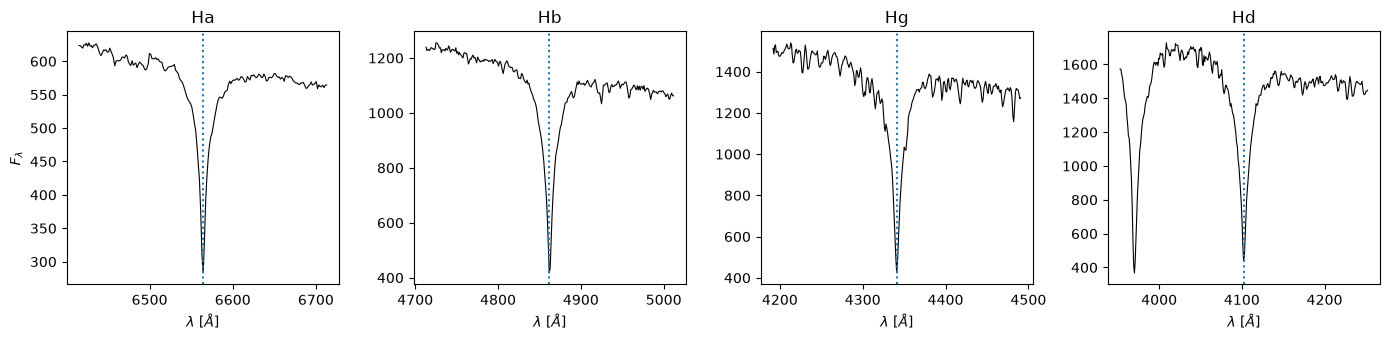

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, name in zip(axes, ["Ha", "Hb", "Hg", "Hd"]):
    w0 = balmer[name] * (1 + z)
    sel = np.abs(spec.wave - w0) < 150
    ax.plot(spec.wave[sel], spec.flux[sel], lw=0.8, color="k")
    ax.axvline(w0, color="C0", ls=":")
    ax.set_title(name)
    ax.set_xlabel(r"$\lambda$ [$\AA$]")
axes[0].set_ylabel(r"$F_\lambda$")
fig.tight_layout()
plt.show()